# NN_L5_vol_forecast

**One-day-ahead forecasts of S&P 500 annualised volatility in 2020: HAR and LSTM (mean of 5 seeds) against the observed Garman-Klass volatility.**

Neural Networks and Deep Learning (NN), Lecture 5 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L5/NN_L5_vol_forecast/NN_L5_vol_forecast.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Forecasts of $y_{t+1}=\ln\hat\sigma^2_{GK,t+1}$ on the test period; the crash window 20 Feb - 30 Apr 2020. Retrain with lectures/L5/analysis_L5.py.

crash MSE HAR = 1.014   [vol.crash.har]
crash MSE LSTM = 0.521   [vol.crash.lstm]
crash MSE GARCH = 1.032   [vol.crash.garch]
crash MSE naive = 0.705   [vol.crash.naive]


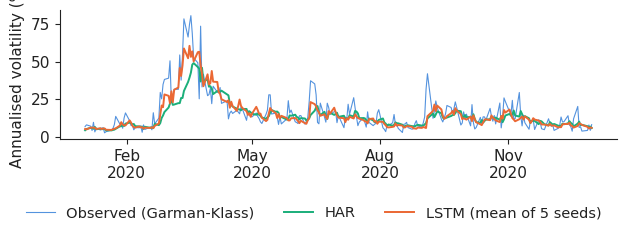

In [3]:
import json, urllib.request
_F = 'vol_forecast_results.json'
R = json.load(open(_F)) if os.path.isfile(_F) else json.load(urllib.request.urlopen(REPO + 'Quantlets/L5/NN_L5_vol_forecast/' + _F))
import matplotlib.dates as mdates
t = pd.to_datetime(R['date']); y = np.array(R['y']); lstm = np.array(R['lstm']).mean(0)
cr = (t >= '2020-02-20') & (t <= '2020-04-30'); mse = lambda p: round(float(np.mean((np.asarray(p)[cr] - y[cr]) ** 2)), 3)
show('vol.crash.har', 'crash MSE HAR', mse(R['har'])); show('vol.crash.lstm', 'crash MSE LSTM', mse(lstm)); show('vol.crash.garch', 'crash MSE GARCH', mse(R['garch'])); show('vol.crash.naive', 'crash MSE naive', mse(R['naive']))
v = lambda a: np.sqrt(252 * np.exp(np.asarray(a))) * 100; m = t.year == 2020
fig, ax = plt.subplots(figsize=(6.4, 2.4))
ax.plot(t[m], v(y)[m], color=PAL['data'], lw=.8, alpha=.8, label='Observed (Garman-Klass)'); ax.plot(t[m], v(R['har'])[m], color=PAL['benchmark'], lw=1.4, label='HAR')
ax.plot(t[m], v(lstm)[m], color=PAL['model'], lw=1.4, label='LSTM (mean of 5 seeds)'); ax.set_ylabel('Annualised volatility (%)')
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3)); ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
legend_bottom(fig, ncol=3); fig.tight_layout(rect=(0, .15, 1, 1))
fig.savefig('vol_forecast.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()